In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
raw = pd.read_csv("titanic_data.csv")
df = raw.copy()
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,no,third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


### Analytical View of a Dataset

In [3]:
df.shape

print(f"Total potential features: {df.shape[1]}")
print(f"Total sample data: {df.shape[0]}")

Total potential features: 12
Total sample data: 891


In [4]:
df.columns = df.columns.str.lower()

In [5]:
df.columns

Index(['passengerid', 'survived', 'pclass', 'name', 'sex', 'age', 'sibsp',
       'parch', 'ticket', 'fare', 'cabin', 'embarked'],
      dtype='str')

In [6]:
df.sample(10)

,passengerid,survived,pclass,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked
559,560,yes,third,"de Messemaeker, Mrs. Guillaume Joseph (Emma)",female,36.0,1,0,345572,17.4000,NaN,S
678,679,no,third,"Goodwin, Mrs. Frederick (Augusta Tyler)",female,43.0,1,6,CA 2144,46.9000,NaN,S
344,345,no,second,"Fox, Mr. Stanley Hubert",male,36.0,0,0,229236,13.0000,NaN,S
3,4,yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
46,47,no,third,"Lennon, Mr. Denis",male,NaN,1,0,370371,15.5000,NaN,Q
252,253,no,first,"Stead, Mr. William Thomas",male,62.0,0,0,113514,26.5500,C87,S
730,731,yes,first,"Allen, Miss. Elisabeth Walton",female,29.0,0,0,24160,211.3375,B5,S
845,846,no,third,"Abbing, Mr. Anthony",male,42.0,0,0,C.A. 5547,7.5500,NaN,S
291,292,yes,first,"Bishop, Mrs. Dickinson H (Helen Walton)",female,19.0,1,0,11967,91.0792,B49,C
647,648,yes,first,"Simonius-Blumer, Col. Oberst Alfons",male,56.0,0,0,13213,35.5000,A26,C


### feature screening

In [7]:
# missing 

df.isnull().sum()

passengerid      0
survived         0
pclass           0
name             0
sex              0
age            177
sibsp            0
parch            0
ticket           0
fare             0
cabin          687
embarked         2
dtype: int64

In [8]:
# checking duplicates

df.duplicated().sum()

np.int64(0)

In [9]:
df.drop_duplicates(inplace=True)

C:\Users\Nazmul Hasan\AppData\Local\Temp\ipykernel_15824\3006716147.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


### Statistical Profiling

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   passengerid  891 non-null    int64  
 1   survived     891 non-null    str    
 2   pclass       891 non-null    str    
 3   name         891 non-null    str    
 4   sex          891 non-null    str    
 5   age          714 non-null    float64
 6   sibsp        891 non-null    int64  
 7   parch        891 non-null    int64  
 8   ticket       891 non-null    str    
 9   fare         891 non-null    float64
 10  cabin        204 non-null    str    
 11  embarked     889 non-null    str    
dtypes: float64(2), int64(3), str(7)
memory usage: 83.7 KB


In [11]:
df.describe()

,passengerid,age,sibsp,parch,fare
count,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,29.699118,0.523008,0.381594,32.204208
std,257.353842,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,38.000000,1.000000,0.000000,31.000000
max,891.000000,80.000000,8.000000,6.000000,512.329200


### Univariate Analysis

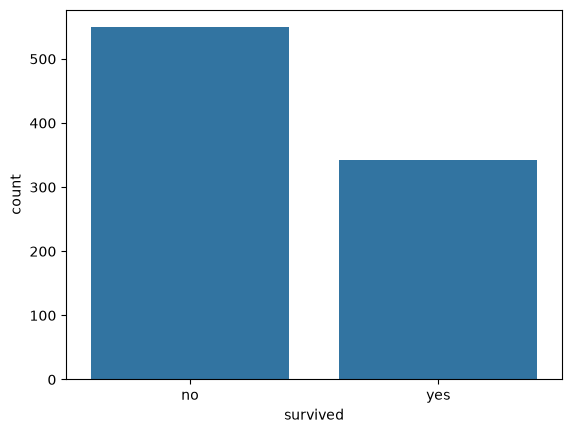

In [12]:
sns.countplot(data=df, x="survived")
plt.show()

In [13]:
(df["survived"].value_counts() / len(df)) * 100

survived
no     61.616162
yes    38.383838
Name: count, dtype: float64

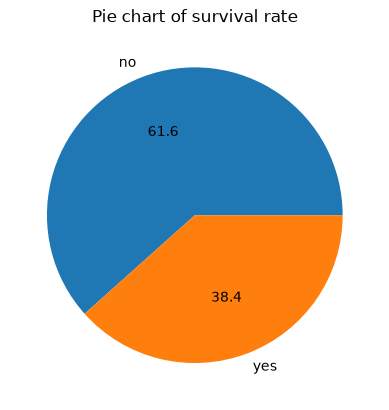

In [14]:
survive_count = df["survived"].value_counts()

survive_label = df["survived"].unique()

plt.pie(survive_count, labels=survive_label, autopct="%1.1f")
plt.title('Pie chart of survival rate')
plt.show()

<Axes: xlabel='pclass', ylabel='count'>

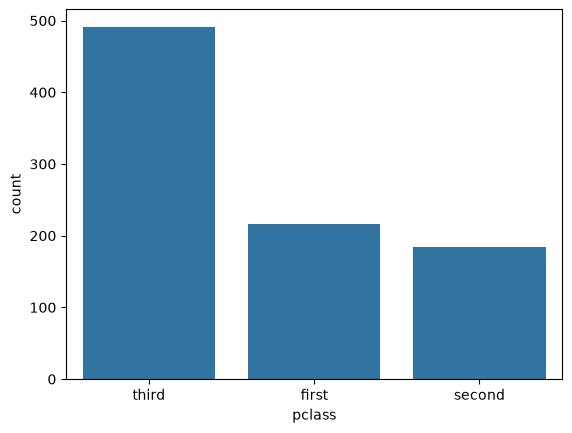

In [15]:
sns.countplot(data = df , x=df['pclass'])

In [16]:
(df["pclass"].value_counts() / len(df) ) * 100

pclass
third     55.106622
first     24.242424
second    20.650954
Name: count, dtype: float64

<Axes: xlabel='sex', ylabel='count'>

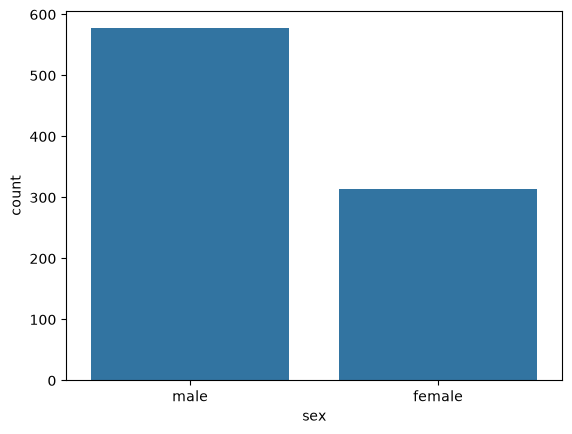

In [17]:
sns.countplot(data=df, x="sex")

In [18]:
(df["sex"].value_counts() / len(df)) * 100

sex
male      64.758698
female    35.241302
Name: count, dtype: float64

<Axes: xlabel='embarked', ylabel='count'>

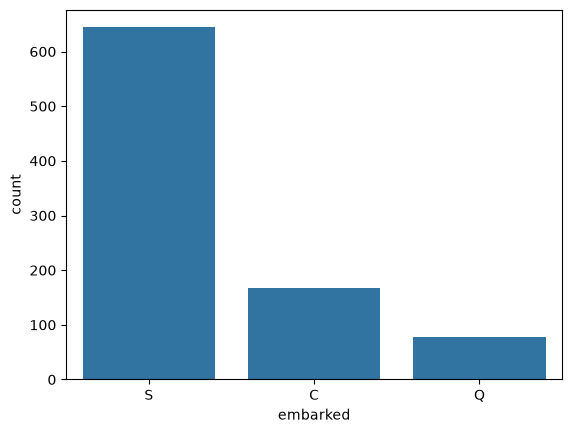

In [19]:
sns.countplot(data = df , x=df['embarked'])

In [20]:
df["embarked"] = df["embarked"].str.replace("S", "Southampton")

In [21]:
df["embarked"] = df["embarked"].str.replace("C", "Cherbourg")

In [22]:
df["embarked"] = df["embarked"].str.replace("Q", "Queenstown")

In [23]:
df["embarked"]

0      Southampton
1        Cherbourg
2      Southampton
3      Southampton
4      Southampton
          ...     
886    Southampton
887    Southampton
888    Southampton
889      Cherbourg
890     Queenstown
Name: embarked, Length: 891, dtype: str

In [24]:
(df['embarked'].value_counts() / len(df) ) * 100

embarked
Southampton    72.278339
Cherbourg      18.855219
Queenstown      8.641975
Name: count, dtype: float64

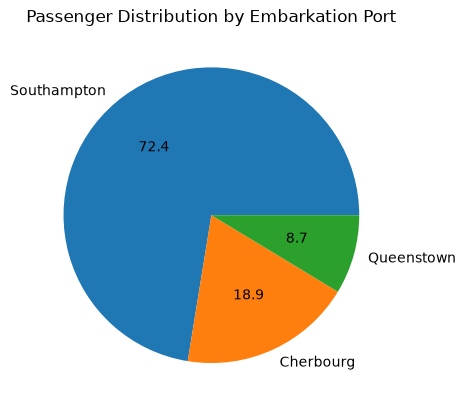

In [25]:
embarked = df["embarked"].value_counts() 
embarked_labels = df["embarked"].unique()

plt.pie(embarked, labels=embarked.index, autopct="%1.1f")
plt.title("Passenger Distribution by Embarkation Port") 
plt.show()

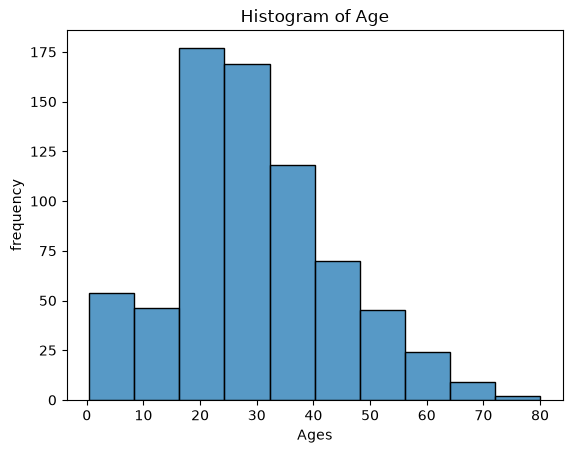

In [26]:
sns.histplot(data=df, x="age", bins=10)

plt.title('Histogram of Age')
plt.xlabel('Ages')
plt.ylabel('frequency')

plt.show()

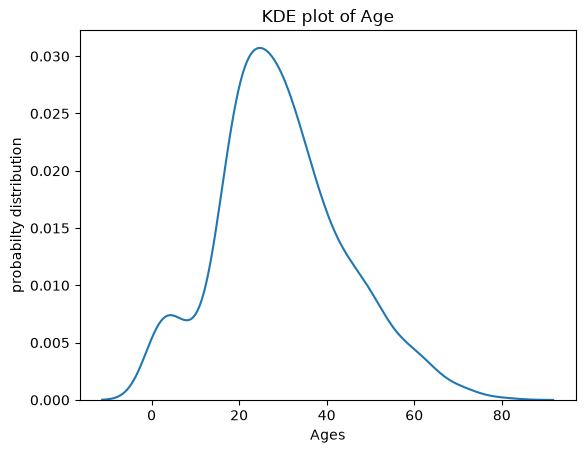

In [27]:
sns.kdeplot(data=df, x="age")
plt.title('KDE plot of Age')
plt.xlabel('Ages')
plt.ylabel('probabilty distribution')

plt.show()

<Axes: xlabel='fare', ylabel='Count'>

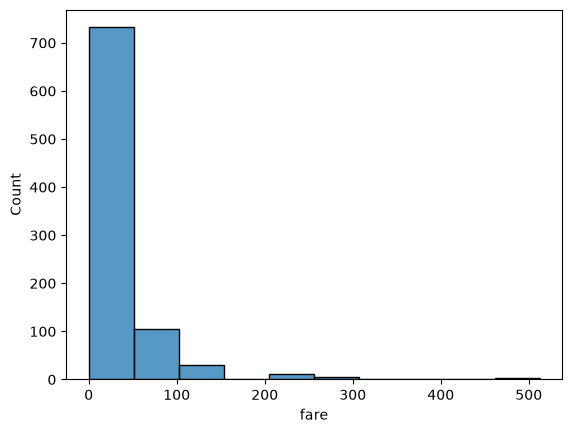

In [28]:
sns.histplot(df["fare"], bins=10)

<Axes: xlabel='fare', ylabel='Density'>

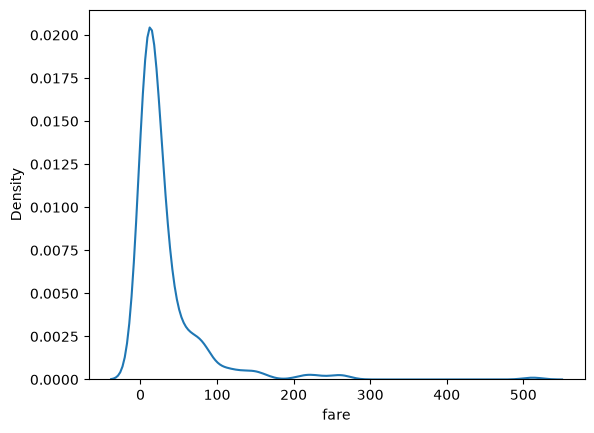

In [29]:
sns.kdeplot(df["fare"])

<Axes: ylabel='fare'>

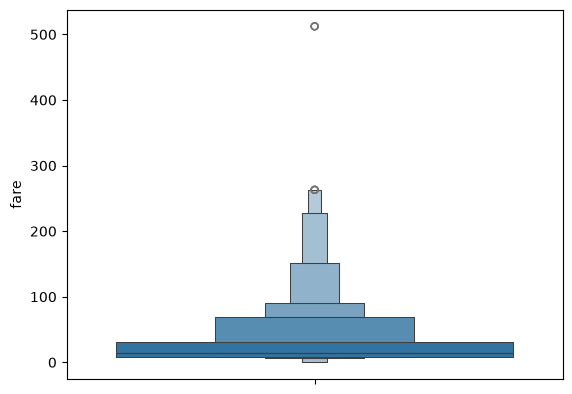

In [30]:
sns.boxenplot(df["fare"])

### Multivariate Analysis

<Axes: xlabel='sex', ylabel='count'>

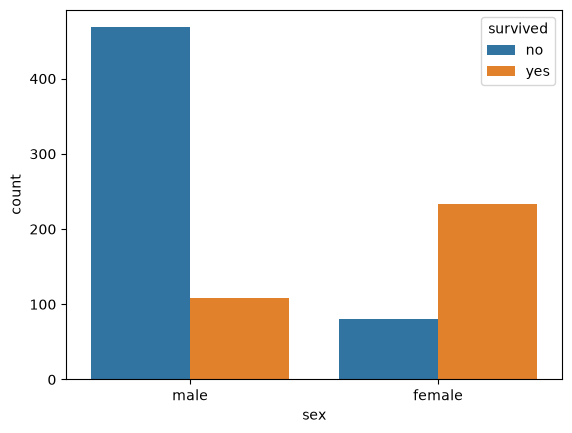

In [31]:
sns.countplot(x=df['sex'],hue=df['survived'])

In [32]:
gender_split = df.groupby('sex')['survived'].value_counts(normalize=True)
gender_split

sex     survived
female  yes         0.742038
        no          0.257962
male    no          0.811092
        yes         0.188908
Name: proportion, dtype: float64

<Axes: xlabel='pclass', ylabel='count'>

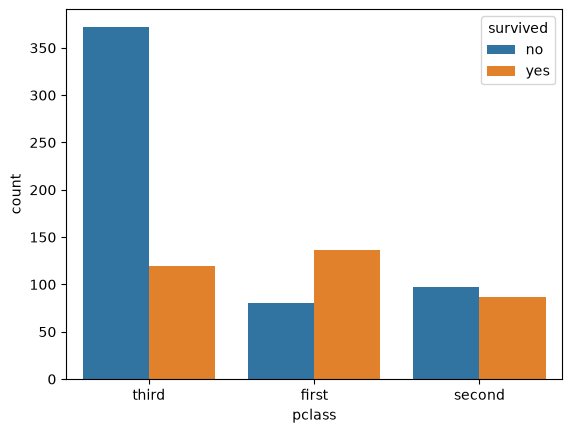

In [33]:
sns.countplot(x=df['pclass'], hue=df['survived'])

In [34]:
pclass_split = df.groupby('pclass')['survived'].value_counts(normalize=True)
pclass_split

pclass  survived
first   yes         0.629630
        no          0.370370
second  no          0.527174
        yes         0.472826
third   no          0.757637
        yes         0.242363
Name: proportion, dtype: float64

<Axes: xlabel='pclass', ylabel='fare'>

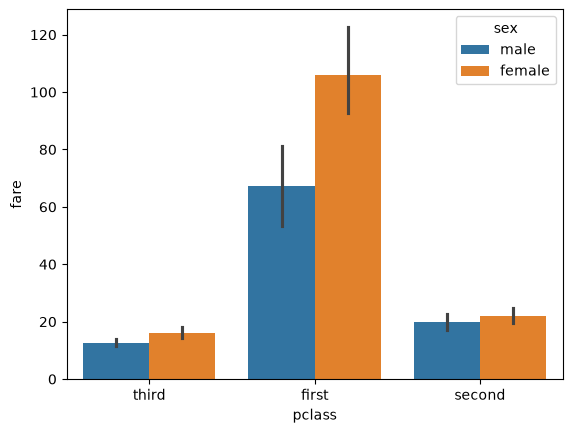

In [35]:
sns.barplot(x=df['pclass'], y=df['fare'], hue=df['sex'])

<Axes: xlabel='survived', ylabel='age'>

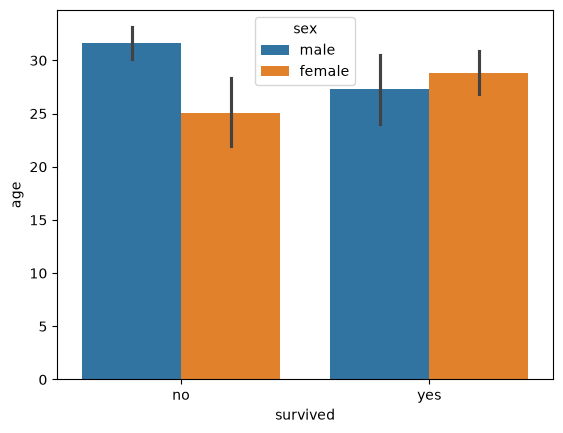

In [36]:
sns.barplot(x=df['survived'],y=df['age'],hue=df['sex'])

<Axes: xlabel='survived', ylabel='age'>

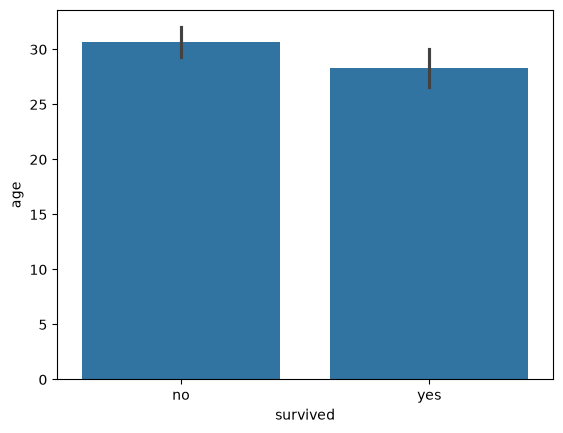

In [37]:
sns.barplot(data=df, x='survived', y='age')

<Axes: xlabel='age', ylabel='Density'>

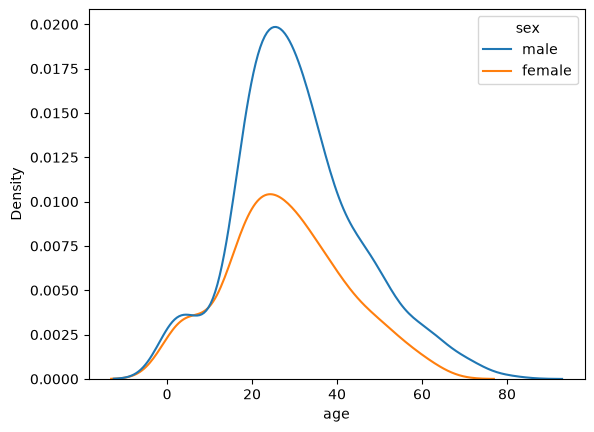

In [38]:
sns.kdeplot(data=df, x='age', hue='sex')

<Axes: xlabel='age', ylabel='Density'>

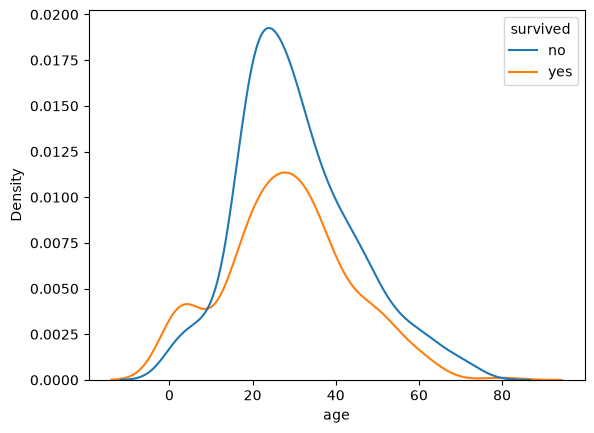

In [39]:
sns.kdeplot(data=df, x='age', hue='survived')

In [40]:
df2 = sns.load_dataset('tips')
df2.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


<Axes: xlabel='total_bill', ylabel='tip'>

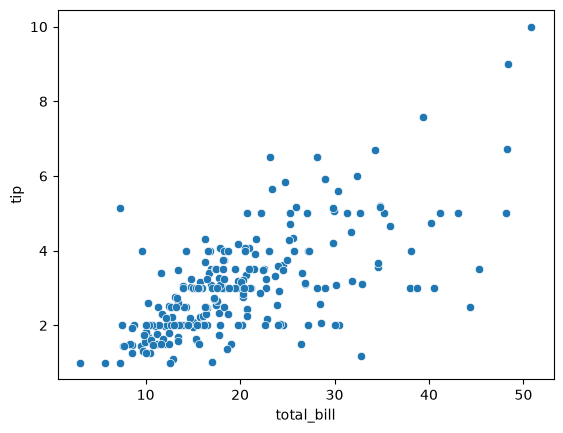

In [41]:
sns.scatterplot(data=df2, x='total_bill', y='tip')

<Axes: xlabel='total_bill', ylabel='tip'>

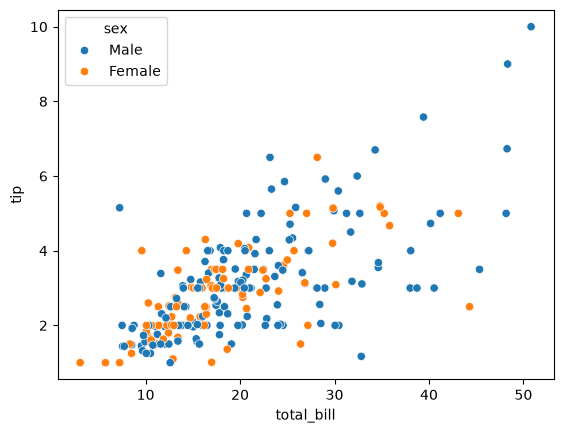

In [42]:
sns.scatterplot(data=df2, x='total_bill', y='tip', hue='sex')

<Axes: xlabel='total_bill', ylabel='tip'>

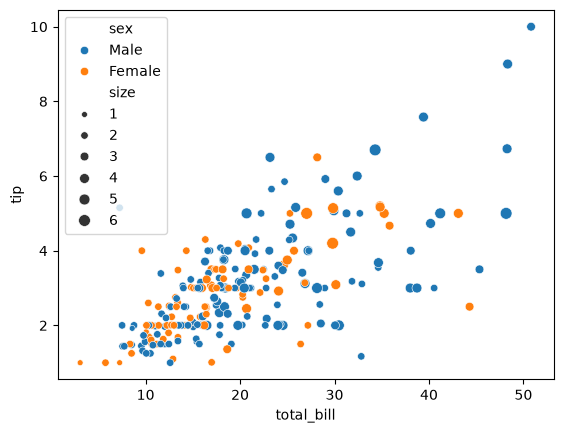

In [43]:
sns.scatterplot(data=df2, x='total_bill', y='tip', hue='sex', size='size')